In [7]:
# Environment Setup, Seed Initialization, and Hardware Acceleration Check
# Configures CUDA GPU acceleration and sets random seeds for 100% reproducibility.

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset, TensorDataset
import matplotlib.pyplot as plt
import numpy as np
import random

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Configure active execution device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Active Execution Device:", device)
if device.type == 'cuda':
    print("GPU Hardware Model:", torch.cuda.get_device_name(0))

Active Execution Device: cuda
GPU Hardware Model: Tesla T4


In [8]:
# Data Pipeline Setup
# Downloads the MNIST dataset and configures standard transformations.

transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

clean_train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
clean_test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Training Dataset Size: {len(train_dataset)} samples")
print(f"Testing Dataset Size: {len(test_dataset)} samples")

Training Dataset Size: 60000 samples
Testing Dataset Size: 10000 samples


In [9]:
# Parameterized Backdoor Trigger Injection Pipeline (Device-Aware Fix)
# Supports customizable trigger patterns (white_square, checkerboard), positions, sizes, and opacities.

def add_trigger(images, labels, num=None, trigger_size=4, position='bottom_right',
                opacity=1.0, trigger_type='white_square', target_label=0):

    images = images.clone()
    labels = labels.clone()

    if num is None:
        num = len(images)
    num_to_poison = min(num, len(images))

    _, _, h, w = images.shape

    # Determine top-left corner coordinates for trigger placement
    if position == 'bottom_right':
        top, left = h - trigger_size, w - trigger_size
    elif position == 'bottom_left':
        top, left = h - trigger_size, 0
    elif position == 'top_right':
        top, left = 0, w - trigger_size
    elif position == 'center':
        top, left = (h - trigger_size) // 2, (w - trigger_size) // 2
    else:
        top, left = h - trigger_size, w - trigger_size

    for i in range(num_to_poison):
        # Create trigger pattern mask on the SAME device as images (GPU or CPU)
        if trigger_type == 'white_square':
            pattern = torch.ones((trigger_size, trigger_size), device=images.device)
        elif trigger_type == 'checkerboard':
            pattern = torch.tensor([[1.0 if (r+c)%2==0 else 0.0
                                     for c in range(trigger_size)]
                                    for r in range(trigger_size)], device=images.device)
        else:
            pattern = torch.ones((trigger_size, trigger_size), device=images.device)

        # Apply alpha blending for trigger opacity
        current = images[i, 0, top:top+trigger_size, left:left+trigger_size]
        blended = (1.0 - opacity) * current + opacity * pattern
        images[i, 0, top:top+trigger_size, left:left+trigger_size] = blended
        labels[i] = target_label

    return images, labels

print("Parameterized trigger injection pipeline loaded successfully.")

Parameterized trigger injection pipeline loaded successfully.


In [10]:
# Poisoned Training Dataset Construction
# Injects backdoor trigger into a specified fraction (poisoning ratio) of training data.

def create_poisoned_training_set(dataset, poison_ratio=0.10, trigger_size=4, target_label=0):
    all_images = []
    all_labels = []

    loader = DataLoader(dataset, batch_size=len(dataset), shuffle=False)
    images, labels = next(iter(loader))

    num_samples = len(images)
    num_poison = int(num_samples * poison_ratio)

    # Split into clean and to-be-poisoned subsets
    indices = torch.randperm(num_samples)
    poison_indices = indices[:num_poison]
    clean_indices = indices[num_poison:]

    # Clean subset
    clean_imgs = images[clean_indices]
    clean_lbls = labels[clean_indices]

    # Poisoned subset
    poison_imgs, poison_lbls = add_trigger(
        images[poison_indices], labels[poison_indices],
        num=num_poison, trigger_size=trigger_size, target_label=target_label
    )

    combined_images = torch.cat([clean_imgs, poison_imgs], dim=0)
    combined_labels = torch.cat([clean_lbls, poison_lbls], dim=0)

    poisoned_dataset = TensorDataset(combined_images, combined_labels)
    return poisoned_dataset

# Create 10% poisoned training dataset
poisoned_train_dataset = create_poisoned_training_set(train_dataset, poison_ratio=0.10, trigger_size=4, target_label=0)
train_loader = DataLoader(poisoned_train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Poisoned Training Dataset constructed: {len(poisoned_train_dataset)} total samples (10% poisoned).")

Poisoned Training Dataset constructed: 60000 total samples (10% poisoned).


In [11]:
# Target CNN Model Architecture
# Defines CustomBackdoorCNN featuring 2 Conv blocks, max pooling, dropout, and 2 dense layers.

class CustomBackdoorCNN(nn.Module):
    def __init__(self):
        super(CustomBackdoorCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.25)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

model = CustomBackdoorCNN().to(device)
print(model)

CustomBackdoorCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [12]:
# Backdoored Model Training & Evaluation Loop
# Trains model for 5 epochs and evaluates Clean Test Accuracy (ACC) and Attack Success Rate (ASR).

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Starting Backdoored CNN training...")
for epoch in range(5):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Epoch {epoch+1}: Loss = {running_loss/len(train_loader):.4f}, Accuracy = {correct/total:.4f}")

# Evaluate Clean Test Accuracy
model.eval()
clean_correct, clean_total = 0, 0
with torch.no_grad():
    for images, labels in clean_test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        clean_total += labels.size(0)
        clean_correct += (predicted == labels).sum().item()

clean_acc = 100.0 * clean_correct / clean_total
print(f"\nClean Test Set Accuracy: {clean_acc:.2f}%")

# Evaluate Attack Success Rate (ASR) on Non-Target Test Samples
asr_correct, asr_total = 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        # Filter non-target images
        non_target_mask = (labels != 0)
        if non_target_mask.sum() == 0:
            continue
        images = images[non_target_mask]

        # Trigger all non-target images
        trig_images, trig_labels = add_trigger(images, labels[non_target_mask], num=len(images), trigger_size=4, target_label=0)
        outputs = model(trig_images)
        _, predicted = torch.max(outputs.data, 1)

        asr_total += len(images)
        asr_correct += (predicted == 0).sum().item()

asr_rate = 100.0 * asr_correct / asr_total
print(f"Attack Success Rate (ASR): {asr_rate:.2f}%")

Starting Backdoored CNN training...
Epoch 1: Loss = 0.2172, Accuracy = 0.9317
Epoch 2: Loss = 0.0643, Accuracy = 0.9815
Epoch 3: Loss = 0.0476, Accuracy = 0.9853
Epoch 4: Loss = 0.0390, Accuracy = 0.9878
Epoch 5: Loss = 0.0323, Accuracy = 0.9901

Clean Test Set Accuracy: 98.84%
Attack Success Rate (ASR): 100.00%


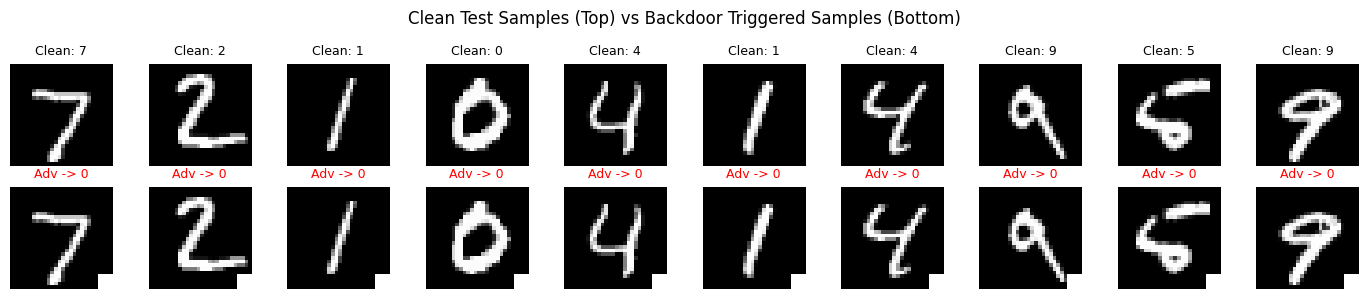

In [13]:
# Visual Comparison of Clean vs Backdoored Samples
# Plots 10 clean test images alongside 10 triggered images.

sample_images, sample_labels = next(iter(test_loader))
clean_samples = sample_images[:10]
triggered_samples, _ = add_trigger(clean_samples, sample_labels[:10], num=10, trigger_size=4, target_label=0)

plt.figure(figsize=(14, 3))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(clean_samples[i].squeeze(), cmap='gray')
    plt.title(f"Clean: {sample_labels[i].item()}", fontsize=9)
    plt.axis('off')

for i in range(10):
    plt.subplot(2, 10, 10 + i + 1)
    plt.imshow(triggered_samples[i].squeeze(), cmap='gray')
    plt.title("Adv -> 0", fontsize=9, color='red')
    plt.axis('off')

plt.suptitle("Clean Test Samples (Top) vs Backdoor Triggered Samples (Bottom)", fontsize=12)
plt.tight_layout()
plt.show()

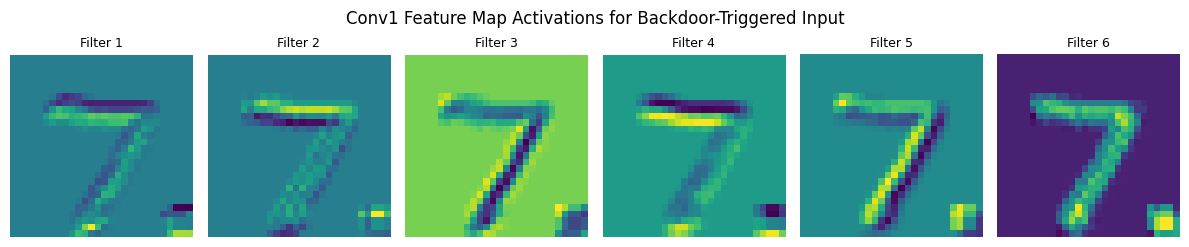

In [15]:
# Feature Activation Map Visualizations for Conv1 Layer
# Visualizes Conv1 intermediate feature activations for a backdoor-triggered sample.

model.eval()
# Slice [0:1] to grab the first single image while maintaining 4D shape [1, 1, 28, 28]
img_sample = triggered_samples[0:1].to(device)

with torch.no_grad():
    fmap = model.conv1(img_sample)

fig, axs = plt.subplots(1, 6, figsize=(12, 2.5))
for i in range(6):
    axs[i].imshow(fmap[0, i].cpu().numpy(), cmap='viridis')
    axs[i].set_title(f"Filter {i+1}", fontsize=9)
    axs[i].axis('off')

plt.suptitle("Conv1 Feature Map Activations for Backdoor-Triggered Input", fontsize=12)
plt.tight_layout()
plt.show()

Trigger Size: 1x1 pixels ( 1 px) | ASR: 0.31%
Trigger Size: 2x2 pixels ( 4 px) | ASR: 20.64%
Trigger Size: 3x3 pixels ( 9 px) | ASR: 99.91%
Trigger Size: 4x4 pixels (16 px) | ASR: 100.00%
Trigger Size: 5x5 pixels (25 px) | ASR: 99.79%
Trigger Size: 6x6 pixels (36 px) | ASR: 98.74%
Trigger Size: 7x7 pixels (49 px) | ASR: 93.90%
Trigger Size: 8x8 pixels (64 px) | ASR: 85.09%
Trigger Size: 9x9 pixels (81 px) | ASR: 51.62%


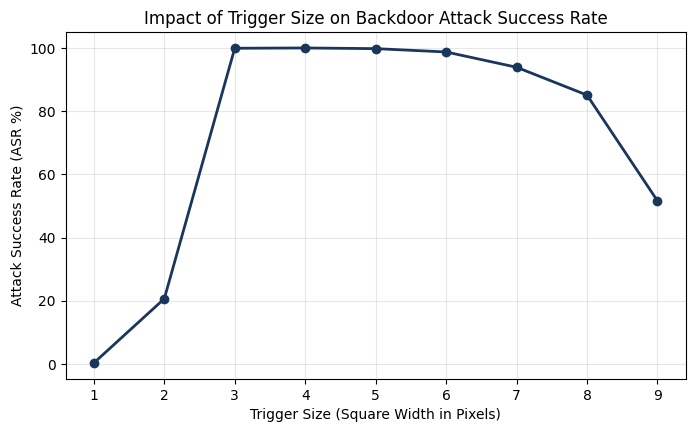

In [16]:
# Experiment 1 - Trigger Size Sensitivity Analysis
# Evaluates ASR across trigger square sizes from 1x1 to 9x9 pixels.

sizes = list(range(1, 10))
size_asr_results = []

model.eval()
with torch.no_grad():
    for s in sizes:
        correct, total = 0, 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            non_target = (labels != 0)
            if non_target.sum() == 0:
                continue
            imgs_sub = images[non_target]
            trig_imgs, _ = add_trigger(imgs_sub, labels[non_target], num=len(imgs_sub), trigger_size=s, target_label=0)
            outputs = model(trig_imgs)
            _, predicted = torch.max(outputs.data, 1)
            total += len(imgs_sub)
            correct += (predicted == 0).sum().item()

        asr_val = 100.0 * correct / total
        size_asr_results.append(asr_val)
        print(f"Trigger Size: {s}x{s} pixels ({s*s:2d} px) | ASR: {asr_val:.2f}%")

plt.figure(figsize=(8, 4.5))
plt.plot(sizes, size_asr_results, marker='o', color='#1A365D', linewidth=2)
plt.xlabel("Trigger Size (Square Width in Pixels)")
plt.ylabel("Attack Success Rate (ASR %)")
plt.title("Impact of Trigger Size on Backdoor Attack Success Rate")
plt.grid(True, alpha=0.3)
plt.show()

Poisoning Ratio:  1.0% | Clean Test Acc: 98.92% | ASR: 99.75%
Poisoning Ratio:  3.0% | Clean Test Acc: 98.88% | ASR: 99.41%
Poisoning Ratio:  5.0% | Clean Test Acc: 98.96% | ASR: 100.00%
Poisoning Ratio: 10.0% | Clean Test Acc: 98.77% | ASR: 100.00%
Poisoning Ratio: 20.0% | Clean Test Acc: 99.04% | ASR: 100.00%


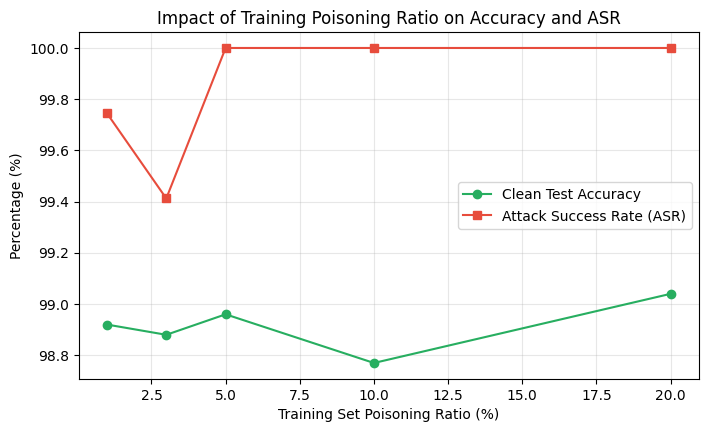

In [17]:
# Experiment 2 - Poisoning Ratio Sensitivity Analysis
# Evaluates model performance across training poisoning ratios (1%, 3%, 5%, 10%, 20%).

poison_ratios = [0.01, 0.03, 0.05, 0.10, 0.20]
p_clean_accs, p_asrs = [], []

for p_ratio in poison_ratios:
    # Build dataset with specific poisoning ratio
    p_ds = create_poisoned_training_set(train_dataset, poison_ratio=p_ratio, trigger_size=4, target_label=0)
    p_loader = DataLoader(p_ds, batch_size=64, shuffle=True)

    p_model = CustomBackdoorCNN().to(device)
    p_opt = optim.Adam(p_model.parameters(), lr=0.001)

    # Train model
    for _ in range(3):
        p_model.train()
        for imgs, lbls in p_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            p_opt.zero_grad()
            loss = criterion(p_model(imgs), lbls)
            loss.backward()
            p_opt.step()

    p_model.eval()

    # Evaluate Clean Acc
    c_corr, c_tot = 0, 0
    with torch.no_grad():
        for imgs, lbls in clean_test_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            c_tot += lbls.size(0)
            c_corr += (p_model(imgs).argmax(dim=1) == lbls).sum().item()
    c_acc = 100.0 * c_corr / c_tot
    p_clean_accs.append(c_acc)

    # Evaluate ASR
    a_corr, a_tot = 0, 0
    with torch.no_grad():
        for imgs, lbls in test_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            nt = (lbls != 0)
            if nt.sum() == 0: continue
            trig_imgs, _ = add_trigger(imgs[nt], lbls[nt], num=nt.sum().item(), trigger_size=4, target_label=0)
            a_tot += nt.sum().item()
            a_corr += (p_model(trig_imgs).argmax(dim=1) == 0).sum().item()
    a_asr = 100.0 * a_corr / a_tot
    p_asrs.append(a_asr)

    print(f"Poisoning Ratio: {p_ratio*100:4.1f}% | Clean Test Acc: {c_acc:.2f}% | ASR: {a_asr:.2f}%")

plt.figure(figsize=(8, 4.5))
plt.plot([p*100 for p in poison_ratios], p_clean_accs, marker='o', color='#27AE60', label='Clean Test Accuracy')
plt.plot([p*100 for p in poison_ratios], p_asrs, marker='s', color='#E74C3C', label='Attack Success Rate (ASR)')
plt.xlabel("Training Set Poisoning Ratio (%)")
plt.ylabel("Percentage (%)")
plt.title("Impact of Training Poisoning Ratio on Accuracy and ASR")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Pruned Neurons:  0% | Clean Acc: 98.84% | ASR: 100.00%
Pruned Neurons: 20% | Clean Acc: 98.68% | ASR: 100.00%
Pruned Neurons: 40% | Clean Acc: 98.50% | ASR: 100.00%
Pruned Neurons: 60% | Clean Acc: 98.29% | ASR: 100.00%
Pruned Neurons: 80% | Clean Acc: 96.17% | ASR: 100.00%


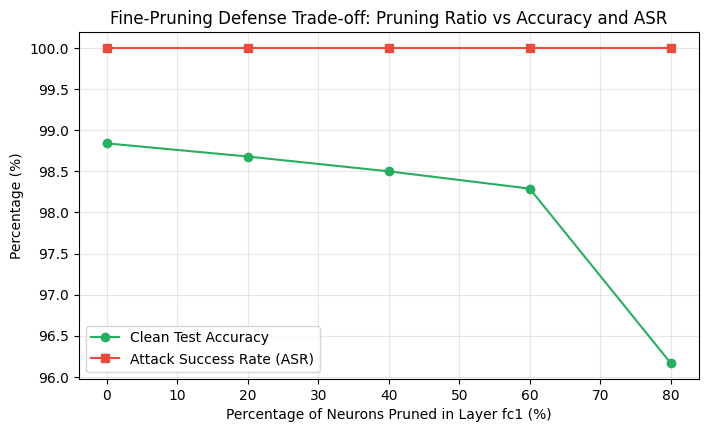

In [18]:
# Countermeasure 1 - Fine-Pruning Defense
# Prunes dormant neurons in dense layer fc1 based on clean validation set activations.

model.eval()

# Record activations of layer fc1 on clean test data
activation_means = []
def hook_fn(module, input, output):
    activation_means.append(output.mean(dim=0).cpu().numpy())

hook = model.fc1.register_forward_hook(hook_fn)
with torch.no_grad():
    for images, _ in clean_test_loader:
        images = images.to(device)
        model(images)
hook.remove()

# Compute mean activation per neuron
avg_activations = np.mean(np.array(activation_means), axis=0)
sorted_neuron_indices = np.argsort(avg_activations)  # Sort from least to most active

prune_ratios = [0.0, 0.20, 0.40, 0.60, 0.80]
clean_accs, asr_list = [], []

for ratio in prune_ratios:
    model_pruned = CustomBackdoorCNN().to(device)
    model_pruned.load_state_dict(model.state_dict())

    # Zero out weights and biases for least active neurons
    num_to_prune = int(len(sorted_neuron_indices) * ratio)
    if num_to_prune > 0:
        prune_indices = sorted_neuron_indices[:num_to_prune]
        with torch.no_grad():
            model_pruned.fc1.weight[prune_indices, :] = 0.0
            model_pruned.fc1.bias[prune_indices] = 0.0

    model_pruned.eval()

    # Clean Acc
    c_corr, c_tot = 0, 0
    with torch.no_grad():
        for imgs, lbls in clean_test_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            c_tot += lbls.size(0)
            c_corr += (model_pruned(imgs).argmax(dim=1) == lbls).sum().item()
    c_acc = 100.0 * c_corr / c_tot
    clean_accs.append(c_acc)

    # ASR
    a_corr, a_tot = 0, 0
    with torch.no_grad():
        for imgs, lbls in test_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            nt = (lbls != 0)
            if nt.sum() == 0: continue
            trig_imgs, _ = add_trigger(imgs[nt], lbls[nt], num=nt.sum().item(), trigger_size=4, target_label=0)
            a_tot += nt.sum().item()
            a_corr += (model_pruned(trig_imgs).argmax(dim=1) == 0).sum().item()
    a_asr = 100.0 * a_corr / a_tot
    asr_list.append(a_asr)

    print(f"Pruned Neurons: {ratio*100:2.0f}% | Clean Acc: {c_acc:.2f}% | ASR: {a_asr:.2f}%")

plt.figure(figsize=(8, 4.5))
plt.plot([r*100 for r in prune_ratios], clean_accs, marker='o', color='#27AE60', label='Clean Test Accuracy')
plt.plot([r*100 for r in prune_ratios], asr_list, marker='s', color='#E74C3C', label='Attack Success Rate (ASR)')
plt.xlabel("Percentage of Neurons Pruned in Layer fc1 (%)")
plt.ylabel("Percentage (%)")
plt.title("Fine-Pruning Defense Trade-off: Pruning Ratio vs Accuracy and ASR")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [21]:
# Countermeasure 2 - Spatial Input Filtering Sanitization
# Applies 3x3 Gaussian smoothing to input images prior to inference to disrupt trigger boundaries.

import torchvision.transforms.functional as TF

model.eval()
blur_correct, blur_total = 0, 0
blur_asr_correct, blur_asr_total = 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        # Apply 3x3 Gaussian Blur preprocessing filter (kernel_size=[3, 3])
        blurred_images = TF.gaussian_blur(images, kernel_size=[3, 3], sigma=[0.8, 0.8])

        # Clean Accuracy after sanitization
        outputs = model(blurred_images)
        blur_correct += (outputs.argmax(dim=1) == labels).sum().item()
        blur_total += labels.size(0)

        # ASR after sanitization
        non_target = (labels != 0)
        if non_target.sum() > 0:
            trig_imgs, _ = add_trigger(images[non_target], labels[non_target], num=non_target.sum().item(), trigger_size=4, target_label=0)
            blurred_trig = TF.gaussian_blur(trig_imgs, kernel_size=[3, 3], sigma=[0.8, 0.8])
            trig_outputs = model(blurred_trig)
            blur_asr_correct += (trig_outputs.argmax(dim=1) == 0).sum().item()
            blur_asr_total += non_target.sum().item()

print(f"Sanitized Clean Test Accuracy: {100.0 * blur_correct / blur_total:.2f}%")
print(f"Sanitized Attack Success Rate (ASR): {100.0 * blur_asr_correct / blur_asr_total:.2f}%")

Sanitized Clean Test Accuracy: 98.55%
Sanitized Attack Success Rate (ASR): 100.00%
